# Climate finance and forest-restoration potential

## Purpose and scope

This deep dive follows two separate calculations. The first distributes the hypothetical 2% GCW allocation across study entities and economic groups. The second reconstructs forest-restoration costs and supply from the public cell-level Busch inputs.

The restoration calculation runs for every country `.dta` file in the archive before any link to FRA losses or to the study entities. A later ISO3 join attaches positive FRA-loss targets to the already calculated country outputs. The 2% allocation is not observed finance or an estimated funding need, and the restoration scenario does not directly price protection of existing forests.

## Load the allocation, all-country restoration outputs and the later target join

The country-cost files describe every `.dta` input processed from the Busch archive. The separate coverage file contains only study entities with positive FRA loss and records whether an ISO3-matched country calculation is available. A country without a positive-loss target remains in the all-country cost files; it is simply absent from that target-coverage table.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repo_root(start):
    for candidate in (start, *start.parents):
        if (candidate / "code" / "notebooks").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the repository from the notebook working directory.")

ROOT = find_repo_root(Path.cwd().resolve())
while ROOT != ROOT.parent and not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'pyproject.toml').is_file():
    raise FileNotFoundError('Run this notebook from within the repository.')

DATA = ROOT / 'data' / 'derived'
RESULTS = ROOT / 'results'
TABLES = RESULTS / 'tables' / 'manuscript'
VALIDATION = ROOT / 'data' / 'derived' / 'validation'
BUSCH_DIR = DATA / 'busch_reconstruction'
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
print(f'Repository: {ROOT}')

Repository: C:\Users\aurel\Desktop\M2\Stage ecoseas-csm\CSM\BNC2 paper\repo


## 2. Examine how the 2% GCW scenario is distributed

The allocation is proportional to the annual GCW value of each eligible study unit, then summarized by economic group. Compare both the total assigned to a group and its share of the global scenario; the median per-unit value describes a different aspect of the distribution.

In [2]:
allocation = pd.read_csv(TABLES / 'Table4_our_2pct_gcw_allocation.csv')
assumptions = pd.read_csv(TABLES / 'Supplementary_deforestation_scenarios.csv')
accounts = pd.read_csv(TABLES / 'Supplementary_country_level_accounts_2024.csv')

# Reconstruct the stipulated allocation from annual GCW and compare group sums with Table 4.
allocation_rate = 0.02
gcw = pd.to_numeric(accounts['gcw_usd2015_yr_mean'], errors='coerce')
exclude = accounts['exclude_from_country_sum'].fillna(False).astype(bool)
eligible = gcw.notna() & ~exclude
accounts.loc[eligible, 'reconstructed_allocation_usd2015_yr'] = allocation_rate * gcw.loc[eligible]
reconstructed = accounts.loc[eligible].groupby('groups', dropna=False)['reconstructed_allocation_usd2015_yr'].sum().div(1e9).rename('reconstructed_billion_usd2015').reset_index()
comparison = allocation.merge(reconstructed, left_on='group', right_on='groups', how='outer')
comparison['difference_billion_usd2015'] = comparison['reconstructed_billion_usd2015'] - comparison['annual_allocation_billion_usd2015']
display(comparison)
display(assumptions.loc[assumptions['metric'].astype(str).str.contains('rate|allocation|discount', case=False, na=False)])


C:\Users\aurel\AppData\Local\Temp\ipykernel_14776\1590006676.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  accounts.loc[eligible, 'reconstructed_allocation_usd2015_yr'] = allocation_rate * gcw.loc[eligible]


,group,units,annual_allocation_billion_usd2015,share_of_total_pct,median_allocation_per_unit_million_usd2015,groups,reconstructed_billion_usd2015,difference_billion_usd2015
0,Developed economies,62,72.239007,43.720574,113.724556,Developed economies,72.239007,8.795382e-10
1,Developing economies,80,68.601312,41.518964,156.314013,Developing economies,68.601312,-7.365813e-09
2,LDCs,37,21.089087,12.763561,185.188891,LDCs,21.089087,-3.881979e-10
3,SIDS,57,3.299455,1.996900,1.259196,SIDS,3.299455,-3.763221e-10
4,Total,236,165.228860,100.000000,NaN,NaN,NaN,NaN
5,Unclassified,0,0.000000,0.000000,NaN,NaN,NaN,NaN


,metric,value,unit,assumption_or_formula,discount_rate,our_allocation_rate
4,Perpetuity value of annual lost GCW at 2% disc...,0.933854,trillion US$2015,Annual lost GCW value / 0.02; perpetual consta...,0.02,NaN


### Visual summary: annual allocation by economic group

The bars show the hypothetical annual amount assigned under the same 2% rule. They do not show payments made, pledged finance or a recommended contribution.

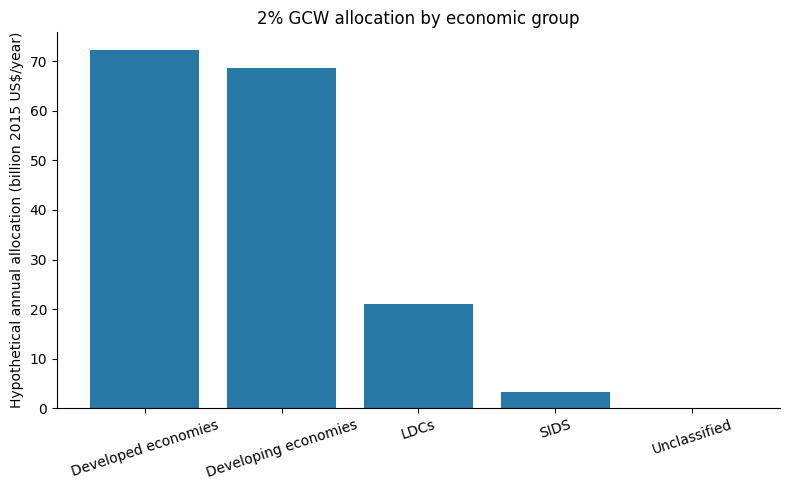

In [3]:
allocation_plot = allocation.loc[allocation["group"].ne("Total")].copy()
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(allocation_plot["group"], allocation_plot["annual_allocation_billion_usd2015"], color="#2878A5")
ax.set_ylabel("Hypothetical annual allocation (billion 2015 US$/year)")
ax.set_title("2% GCW allocation by economic group")
ax.tick_params(axis="x", rotation=18)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 3. Examine restoration supply and costs for every archive country

The country-cost output is calculated from each country `.dta` file independently of FRA loss and study-table coverage. Use it to inspect all calculated country supplies and cost curves. The coverage table is created afterward: it joins only positive FRA-loss targets by ISO3 so that those targets can be compared with the previously calculated supply. No published national curve is used to select or validate the calculation.

,measure,count
0,Country DTA files in archive,138
1,Country DTA files processed,138
2,Study entities with positive FRA loss,100
3,Positive-loss entities with a country DTA,69
4,Positive-loss entities without a country DTA,31


,iso3,output_cells,selected_natural_regeneration_cells,selected_plantation_cells,available_discounted_tco2
12,BRA,8556934,1209728,7187550,3.798820e+10
18,CHN,6189576,2831541,3312437,1.827300e+10
74,MEX,1219912,789710,382780,6.844903e+09
54,IND,2447772,1460338,615756,5.080917e+09
24,COL,1096485,742820,342330,4.631660e+09
77,MMR,696217,180911,511726,4.218385e+09
115,THA,523025,14282,506642,3.831602e+09
53,IDN,1800315,1228775,519063,3.669808e+09
130,VEN,804648,230688,571584,3.022627e+09
21,COD,2325739,1341345,913423,2.831171e+09


,iso3,name,groups,reported_loss_capacity_tco2_yr,target_discounted_30yr_tco2,our_2pct_gcw_allocation_usd2015_yr,country_dta_available,cell_input_available,available_discounted_tco2,target_coverage_pct,priced_cells,status,marginal_effective_cost_usd2015_per_discounted_tco2,net_economic_cost_pv_usd2015,positive_project_cost_pv_usd2015,uniform_carbon_payment_pv_usd2015,selected_cells_with_fractional_last,net_economic_cost_annual_usd2015,positive_project_cost_annual_usd2015,uniform_carbon_payment_annual_usd2015,allocation_over_positive_project_cost,allocation_over_uniform_payment,figure4c_category
0,BRA,Brazil,Developing economies,1.126536e+07,1.769475e+08,1.876750e+10,True,True,3.798820e+10,100.0,1142896.0,target_within_cell_supply,-30.465922,-5.694646e+09,0.000000e+00,0.000000e+00,5341.007694,-3.625495e+08,0.00000,0.000000e+00,NaN,NaN,Target within supply; non-positive marginal cost
1,CHN,"China (incl. Taiwan, Hong Kong SAR and Macao SAR)",Developing economies,1.315226e+06,2.065854e+07,1.220267e+10,True,True,1.827300e+10,100.0,1344511.0,target_within_cell_supply,-18.470678,-4.328597e+08,0.000000e+00,0.000000e+00,1291.354253,-2.755800e+07,0.00000,0.000000e+00,NaN,NaN,Target within supply; non-positive marginal cost
2,CAN,Canada,Developed economies,1.491670e+05,2.342999e+06,1.218735e+10,False,False,NaN,NaN,NaN,no_country_input_dta,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No country input DTA
3,AUS,Australia,Developed economies,2.175637e+06,3.417322e+07,7.267759e+09,False,False,NaN,NaN,NaN,no_country_input_dta,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No country input DTA
4,COD,Democratic Republic of the Congo,LDCs,9.713073e+05,1.525654e+07,5.336977e+09,True,True,2.831171e+09,100.0,122280.0,target_within_cell_supply,-24.767213,-4.160350e+08,0.000000e+00,0.000000e+00,317.745277,-2.648685e+07,0.00000,0.000000e+00,NaN,NaN,Target within supply; non-positive marginal cost
5,IDN,Indonesia,Developing economies,3.725915e+05,5.852378e+06,3.679786e+09,True,True,3.669808e+09,100.0,206142.0,target_within_cell_supply,-24.739907,-1.521456e+08,0.000000e+00,0.000000e+00,236.455249,-9.686347e+06,0.00000,0.000000e+00,NaN,NaN,Target within supply; non-positive marginal cost
6,IND,India,Developing economies,2.218650e+06,3.484883e+07,3.050323e+09,True,True,5.080917e+09,100.0,291020.0,target_within_cell_supply,-19.126745,-8.052516e+08,0.000000e+00,0.000000e+00,2279.727623,-5.126632e+07,0.00000,0.000000e+00,NaN,NaN,Target within supply; non-positive marginal cost
7,MEX,Mexico,Developing economies,6.816678e+05,1.070711e+07,3.048671e+09,True,True,6.844903e+09,100.0,356044.0,target_within_cell_supply,-30.269495,-3.505439e+08,0.000000e+00,0.000000e+00,358.960130,-2.231737e+07,0.00000,0.000000e+00,NaN,NaN,Target within supply; non-positive marginal cost
8,AGO,Angola,LDCs,1.748833e+06,2.746931e+07,2.425691e+09,True,True,6.022370e+07,100.0,3143.0,target_within_cell_supply,1.091044,-3.568150e+08,6.206993e+06,2.997023e+07,1062.806193,-2.271661e+07,395168.04092,1.908054e+06,6138.378047,1271.290724,Target within supply; positive marginal cost
9,COL,Colombia,Developing economies,4.571140e+05,7.179992e+06,2.279776e+09,True,True,4.631660e+09,100.0,198444.0,target_within_cell_supply,-31.038859,-2.287701e+08,0.000000e+00,0.000000e+00,202.439241,-1.456464e+07,0.00000,0.000000e+00,NaN,NaN,Target within supply; non-positive marginal cost


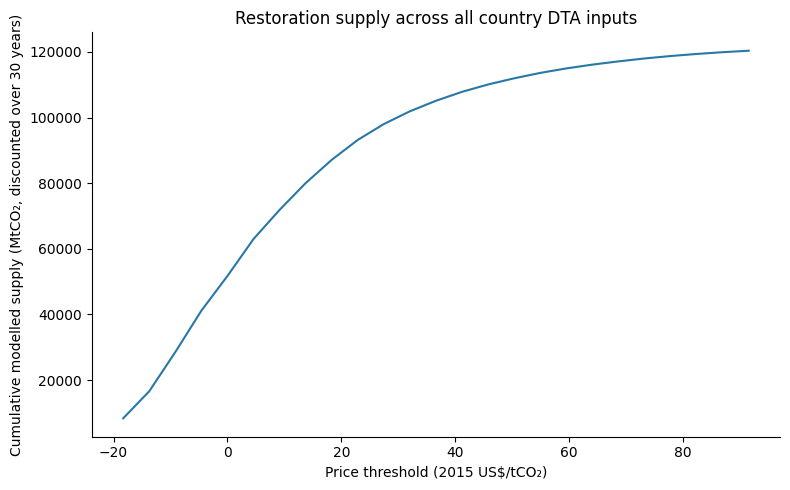

In [4]:
import json

BUSCH_DIR = DATA / "busch_reconstruction"
busch_prefix = "busch_all_dta"
busch_summary = json.loads((BUSCH_DIR / f"{busch_prefix}_summary.json").read_text(encoding="utf-8"))
all_country_costs = pd.read_csv(BUSCH_DIR / f"{busch_prefix}_country_finance.csv")
all_country_price_curves = pd.read_csv(BUSCH_DIR / f"{busch_prefix}_25_price_curves.csv")
positive_loss_coverage = pd.read_csv(BUSCH_DIR / f"{busch_prefix}_coverage.csv")

archive_scope = pd.DataFrame([
    {"measure": "Country DTA files in archive", "count": busch_summary["archive_country_dta_count"]},
    {"measure": "Country DTA files processed", "count": busch_summary["processed_country_dta_count"]},
    {"measure": "Study entities with positive FRA loss", "count": busch_summary["positive_loss_entities"]},
    {"measure": "Positive-loss entities with a country DTA", "count": busch_summary["positive_loss_entities_with_dta"]},
    {"measure": "Positive-loss entities without a country DTA", "count": busch_summary["positive_loss_entities_without_dta"]},
])
display(archive_scope)

display(
    all_country_costs.sort_values("available_discounted_tco2", ascending=False)
    [["iso3", "output_cells", "selected_natural_regeneration_cells",
      "selected_plantation_cells", "available_discounted_tco2"]]
    .head(20)
)
display(positive_loss_coverage.head(20))

# Summing the country-level cumulative curves gives an archive-wide descriptive curve.
archive_price_curve = (
    all_country_price_curves.groupby("price_usd2015_per_tco2", as_index=False)
    ["cumulative_supply_discounted_tco2"].sum()
    .sort_values("price_usd2015_per_tco2")
)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    archive_price_curve["price_usd2015_per_tco2"],
    archive_price_curve["cumulative_supply_discounted_tco2"] / 1e6,
    color="#2878A5",
)
ax.set_xlabel("Price threshold (2015 US$/tCO₂)")
ax.set_ylabel("Cumulative modelled supply (MtCO₂, discounted over 30 years)")
ax.set_title("Restoration supply across all country DTA inputs")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 4. Compare the natural-regeneration soil scenarios

The reference calculation and two soil-rate alternatives are each recalculated for every country `.dta` input. Only after those calculations does a second table join the resulting scenarios to positive FRA-loss targets. The plantation soil rate stays fixed. These are deterministic sensitivity scenarios, not confidence intervals.

,soil_scenario,nr_soil_rate_tC_ha_yr,country_dta_inputs,nr_cells,plantation_cells,method_switches,available_supply_discounted_tco2
0,busch_reference,0.415108,138,25159263,28648927,0,1.203847e+11
1,post_kwon_2000,0.338000,138,25018163,28790027,141100,1.193490e+11
2,zero_soil_change,0.000000,138,20584198,29884733,4575065,1.149296e+11


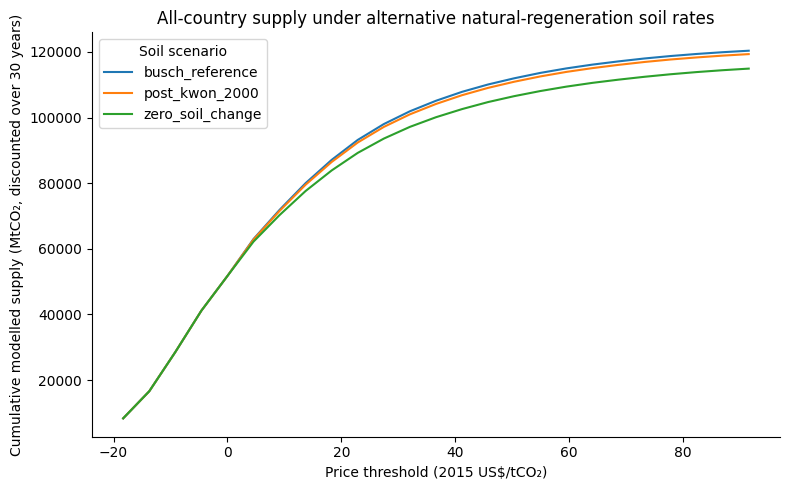

,soil_scenario,status,positive_loss_entities,reported_loss_capacity_tco2_yr
0,busch_reference,no_country_input_dta,31,2.870225e+06
1,busch_reference,target_outside_cell_supply,11,2.578429e+06
2,busch_reference,target_within_cell_supply,58,2.792875e+07
3,post_kwon_2000,no_country_input_dta,31,2.870225e+06
4,post_kwon_2000,target_outside_cell_supply,11,2.578429e+06
5,post_kwon_2000,target_within_cell_supply,58,2.792875e+07
6,zero_soil_change,no_country_input_dta,31,2.870225e+06
7,zero_soil_change,target_outside_cell_supply,12,2.602172e+06
8,zero_soil_change,target_within_cell_supply,57,2.790500e+07


In [5]:
soil_sensitivity_path = BUSCH_DIR / f"{busch_prefix}_soil_sensitivity_country.csv"
sensitivity_curves_path = BUSCH_DIR / f"{busch_prefix}_soil_sensitivity_price_curves.csv"
sensitivity_coverage_path = BUSCH_DIR / f"{busch_prefix}_soil_sensitivity_coverage.csv"

soil_sensitivity = pd.read_csv(soil_sensitivity_path)
sensitivity_summary = (
    soil_sensitivity.groupby("soil_scenario", dropna=False)
    .agg(
        nr_soil_rate_tC_ha_yr=("nr_soil_rate_tC_ha_yr", "first"),
        country_dta_inputs=("iso3", "nunique"),
        nr_cells=("natural_regeneration_cells_selected", "sum"),
        plantation_cells=("plantation_cells_selected", "sum"),
        method_switches=("method_switches_vs_reference", "sum"),
        available_supply_discounted_tco2=("available_discounted_tco2", "sum"),
    )
    .reset_index()
)
display(sensitivity_summary)

sensitivity_curves = pd.read_csv(sensitivity_curves_path)
global_sensitivity_curves = (
    sensitivity_curves.groupby(["soil_scenario", "price_usd2015_per_tco2"], as_index=False)
    ["cumulative_supply_discounted_tco2"].sum()
)
fig, ax = plt.subplots(figsize=(8, 5))
for scenario, rows in global_sensitivity_curves.groupby("soil_scenario"):
    rows = rows.sort_values("price_usd2015_per_tco2")
    ax.plot(
        rows["price_usd2015_per_tco2"],
        rows["cumulative_supply_discounted_tco2"] / 1e6,
        label=scenario,
    )
ax.set_xlabel("Price threshold (2015 US$/tCO₂)")
ax.set_ylabel("Cumulative modelled supply (MtCO₂, discounted over 30 years)")
ax.set_title("All-country supply under alternative natural-regeneration soil rates")
ax.legend(title="Soil scenario")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

soil_sensitivity_coverage = pd.read_csv(sensitivity_coverage_path)
target_sensitivity_summary = (
    soil_sensitivity_coverage.groupby(["soil_scenario", "status"], dropna=False)
    .agg(
        positive_loss_entities=("iso3", "nunique"),
        reported_loss_capacity_tco2_yr=("reported_loss_capacity_tco2_yr", "sum"),
    )
    .reset_index()
)
display(target_sensitivity_summary)

## 5. Read the target-cost results alongside the 2% allocation

The all-country files show the modelled costs and supply for every archive input. Target-cost fields appear in the separate positive-loss coverage table only after the ISO3 join. The 2% GCW allocation remains an annual hypothetical amount in 2015 US dollars; target costs are derived from the 30-year restoration calculation. Their comparison is a scenario comparison, not an observed budget or financing gap.

In [6]:
comparison_path = VALIDATION / "finance_action_cost_comparison.json"
if comparison_path.exists():
    comparison = json.loads(comparison_path.read_text(encoding="utf-8"))
    display(pd.Series(comparison, name="value").to_frame())
else:
    print("The finance comparison summary is not present yet.")

print(
    "All-country Busch DTA processing complete:",
    busch_summary["processing_scope_complete"],
    "| published country-curve comparison performed:",
    busch_summary["published_curve_comparison_performed"],
)

,value
gcw_usd2015_yr,8261443009142.151367
our_allocation_rate,0.02
our_2pct_gcw_allocation_usd2015_yr,165228860182.843018
positive_loss_entities,100
positive_loss_capacity_tco2_yr,33377399.801651
source_discount_factor_30yr,15.707225
restoration_calculation,"all country DTA inputs, before joining positiv..."
published_country_curve_comparison_performed,False
restoration_join_status_counts,"{'target_within_cell_supply': 58, 'no_country_..."


All-country Busch DTA processing complete: True | published country-curve comparison performed: False
